# 01 · The scoring engine

**Goal:** a single, trusted function that turns *what happened in a match* (minutes, goals, saves, tackles…)
into *FPL points*, under **any season's rules**.

Why it matters for the model:
- Our component model predicts **events** (P(clean sheet), expected goals, defensive-action counts…). The scoring
  engine converts those into points. If the engine is wrong, every prediction is wrong.
- FPL rules change (defensive contributions arrived in 2025-26; goalkeeper goals are worth 10 in 2026-27). Because rules
  live in a **table**, not in code, a rule change means updating rows, not rewriting the model.
- It lets us **re-score history under today's rules**, which is what you asked about.

Code: [`fpl_engine/scoring.py`](../fpl_engine/scoring.py) · rules: table `core.scoring_rules`.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db
from fpl_engine.scoring import score, load_rules
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
POS = ['GKP', 'DEF', 'MID', 'FWD']
conn = db.connect()

## 1 · The rules, as data

In [2]:
rules = pd.read_sql("SELECT * FROM core.scoring_rules WHERE season IN ('2024-25','2025-26','2026-27')", conn)
rules['value'] = rules.points_value.astype(float).map('{:g}'.format) + rules.threshold.map(lambda t: '' if pd.isna(t) else f' (≥{float(t):g})')
pivot = rules.pivot_table(index=['event_type'], columns=['season', 'player_position'], values='value', aggfunc='first')
changed = pivot.T.groupby(level=1).nunique().T.max(axis=1) > 1   # differs between seasons for some position
pivot = pivot.reindex(columns=['2024-25', '2025-26', '2026-27'], level=0).reindex(columns=POS, level=1)
pivot.loc[changed[changed].index]

season                 2024-25                            2025-26           \
player_position            GKP      DEF      MID      FWD     GKP      DEF   
event_type                                                                   
defensive_contribution       0  0 (≥10)  0 (≥12)  0 (≥12)       0  2 (≥10)   
goal                         6        6        5        4       6        6   

season                                   2026-27                             
player_position             MID      FWD     GKP      DEF      MID      FWD  
event_type                                                                   
defensive_contribution  2 (≥12)  2 (≥12)       0  2 (≥10)  2 (≥12)  2 (≥12)  
goal                          5        4      10        6        5        4

Only two rules differ across the last three seasons:
- **defensive contribution**: worth nothing before 2025-26; from then, **2 points** when a defender reaches **10**
  clearances+blocks+interceptions+tackles (CBIT), or a midfielder/forward reaches **12** (CBIT + recoveries).
- **goalkeeper goal**: 6 → **10** points in 2026-27 (rare, but it's in the rules).

Everything else (2 points for 60+ minutes, 3 per assist, −1 per 2 goals conceded for GK/DEF, 1 per 3 saves…) is unchanged.

## 2 · Does the engine reproduce official points?

The acid test: take every appearance since 2016-17, apply that season's stored rules to the raw stats,
compare to the points FPL actually awarded.

In [3]:
stats = pd.read_sql('''
    SELECT s.*, ps.position FROM core.player_match_stats s
    JOIN core.player_seasons ps USING (player_id, season)
    WHERE ps.position IN ('GKP','DEF','MID','FWD')''', conn)
results = []
for season, g in stats.groupby('season'):
    pts = score(g, load_rules(conn, season))
    results.append({'season': season, 'appearances': int((g.minutes > 0).sum()),
                    'match %': round(100 * (pts.total == g.fpl_points).mean(), 2)})
check = pd.DataFrame(results).set_index('season'); check

,appearances,match %
season,,
2016-17,10474,100.0
2017-18,10448,100.0
2018-19,10480,100.0
2019-20,10614,100.0
2020-21,10393,100.0
2021-22,10485,100.0
2022-23,11345,100.0
2023-24,11384,100.0
2024-25,11566,100.0


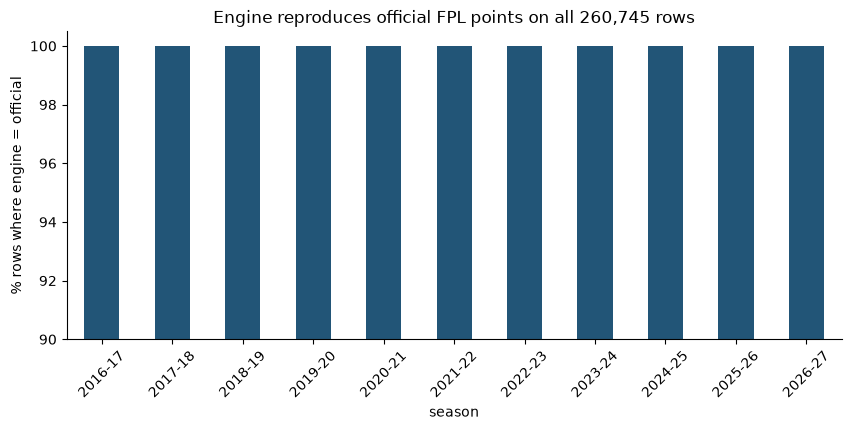

In [4]:
ax = check['match %'].plot.bar(color='#257', rot=45, ylim=(90, 100.5))
ax.set_ylabel('% rows where engine = official'); ax.set_title(f"Engine reproduces official FPL points on all {len(stats):,} rows")
plt.show()

**100% in every season.** This also *proved* some rule history from the data itself: e.g. Alisson's 2020-21 goal
scored 6 points (so GK goals were 6 then), and defensive contributions only reproduce official points from 2025-26.

This check becomes an automated test, so if FPL ever changes a rule mid-season we'll see it immediately.

## 3 · What a points breakdown looks like

In [5]:
cur = stats[(stats.season == '2025-26') & (stats.minutes > 0)]
br = score(cur, load_rules(conn, '2025-26'))
names = pd.read_sql('SELECT player_id, web_name FROM core.players', conn).set_index('player_id').web_name
top = cur.assign(name=cur.player_id.map(names)).join(br.add_prefix('pts_')).sort_values('fpl_points', ascending=False)
top[['name', 'position', 'minutes', 'goals', 'assists', 'clean_sheet', 'defensive_contribution', 'bonus', 'fpl_points',
     'pts_appearance', 'pts_goals', 'pts_assists', 'pts_clean_sheet', 'pts_defensive_contribution', 'pts_bonus']].head(8)

,name,position,minutes,goals,assists,clean_sheet,defensive_contribution,bonus,fpl_points,pts_appearance,pts_goals,pts_assists,pts_clean_sheet,pts_defensive_contribution,pts_bonus
231161,J.Timber,DEF,63,2,1,1,6.0,3,24,2.0,12.0,3.0,4.0,0.0,3.0
236070,Van de Ven,DEF,90,2,0,1,10.0,3,23,2.0,12.0,0.0,4.0,2.0,3.0
254089,Mavropanos,DEF,90,2,0,1,9.0,3,21,2.0,12.0,0.0,4.0,0.0,3.0
242708,Lewis-Potter,DEF,90,2,0,1,3.0,3,21,2.0,12.0,0.0,4.0,0.0,3.0
248699,Palmer,MID,60,3,0,0,1.0,3,20,2.0,15.0,0.0,0.0,0.0,3.0
243298,Schade,MID,90,3,0,0,9.0,3,20,2.0,15.0,0.0,0.0,0.0,3.0
238961,Eze,MID,90,3,0,0,8.0,3,20,2.0,15.0,0.0,0.0,0.0,3.0
255472,Gibbs-White,MID,88,3,0,0,4.0,3,20,2.0,15.0,0.0,0.0,0.0,3.0


This is the same breakdown every prediction will carry, e.g. *"midfielder X: 6.1 xPts = 1.8 appearance + 1.9 goals +
1.1 assists + 0.3 clean sheet + 0.1 defensive + 0.9 bonus"* (illustrative numbers). That's how we keep the model **explainable**.

## 4 · Your question: re-scoring history under today's rules

To train on 2022-23 onwards as if today's rules had always applied, we need each historical stat that today's
rules use. The gap is **defensive-contribution counts**: FPL only published them from 2025-26 (and back in 2016-19).

In [6]:
cov = stats[stats.minutes > 0].groupby('season').agg(
    appearances=('minutes', 'size'),
    has_dc_count=('defensive_contribution', lambda s: round(100 * s.notna().mean(), 1)),
    has_tackles=('tackles', lambda s: round(100 * s.notna().mean(), 1)),
    has_recoveries=('recoveries', lambda s: round(100 * s.notna().mean(), 1)))
cov.loc['2021-22':]

,appearances,has_dc_count,has_tackles,has_recoveries
season,,,,
2021-22,10485,0.0,0.0,0.0
2022-23,11345,0.0,0.0,0.0
2023-24,11384,0.0,0.0,0.0
2024-25,11566,0.0,0.0,0.0
2025-26,11492,100.0,100.0,100.0
2026-27,3365,100.0,100.0,100.0


In [7]:
now = load_rules(conn, '2026-27')
past = stats[(stats.season >= '2022-23') & (stats.minutes > 0)]
rescored = score(past, now)
print('Re-scoring 2022-23 onwards under 2026-27 rules — rows with a KNOWN total:')
print((rescored.total.notna().groupby(past.season).mean() * 100).round(1).to_string())

Re-scoring 2022-23 onwards under 2026-27 rules — rows with a KNOWN total:
season
2022-23      6.8
2023-24      6.8
2024-25      6.7
2025-26    100.0
2026-27    100.0


As expected, 2022-23 → 2024-25 come out **unknown** (NaN), not zero. That's deliberate: treating a missing
defensive count as zero would wrongly tell the model that defenders never earned these points before 2025.

### Can PitchAPI fill the gap?
PitchAPI has per-player clearances, interceptions, blocks, tackles and recoveries for every match since 2021-22.
Before trusting it, we compare it with FPL's own numbers in **2025-26**, where we have both. Player IDs aren't linked
yet, so we compare **team totals per match** (760 team-matches).

760 of 760 team-matches matched


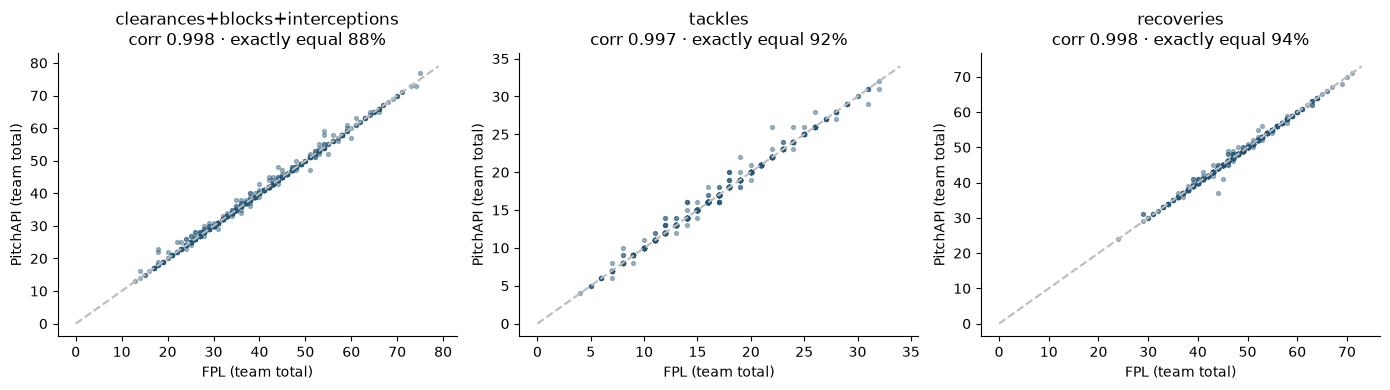

In [8]:
pa = pd.read_sql('''
  SELECT r.entity_id AS match_id, (m.payload->>'date')::date AS date,
         m.payload->'home_team'->>'id' AS home_id, m.payload->'home_team'->>'name' AS home,
         m.payload->'away_team'->>'name' AS away, x->>'team_id' AS team_pid,
         e.k AS stat, (e.v->'stat'->>'value')::float AS value
  FROM raw.provider_records r
  JOIN raw.provider_records m ON m.source_name='pitchapi' AND m.entity='match' AND m.entity_id=r.entity_id
  CROSS JOIN jsonb_array_elements(r.payload) x
  CROSS JOIN jsonb_array_elements(x->'stats') g
  CROSS JOIN jsonb_each(g->'stats') e(k, v)
  WHERE r.source_name='pitchapi' AND r.entity='match_players' AND r.season='2025-26'
    AND e.k IN ('Clearances','Interceptions','Blocks','Tackles','Recoveries')''', conn)
pa['team'] = np.where(pa.team_pid == pa.home_id, pa.home, pa.away)
pt = pa.pivot_table(index=['date', 'team'], columns='stat', values='value', aggfunc='sum').reset_index()

fpl = pd.read_sql('''
  SELECT f.kickoff_time::date AS date, t.team_name AS team, sum(s.clearances_blocks_interceptions) AS cbi,
         sum(s.tackles) AS tackles, sum(s.recoveries) AS recoveries
  FROM core.player_match_stats s JOIN core.fixtures f USING (fixture_id) JOIN core.teams t ON t.team_id = s.team_id
  WHERE s.season = '2025-26' GROUP BY 1, 2''', conn)

import re, unicodedata
def key(s):
    s = re.sub(r'[^a-z]', '', unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode().lower())
    return {'manchestercity': 'mancity', 'manchesterunited': 'manutd', 'tottenhamhotspur': 'spurs',
            'nottinghamforest': 'nottmforest', 'wolverhamptonwanderers': 'wolves', 'brightonhovealbion': 'brighton',
            'afcbournemouth': 'bournemouth', 'newcastleunited': 'newcastle', 'westhamunited': 'westham',
            'leedsunited': 'leeds'}.get(s, s)
pt['key'], fpl['key'] = pt.team.map(key), fpl.team.map(key)
m = pt.merge(fpl, on=['date', 'key'])
print(f'{len(m)} of {len(pt)} team-matches matched')
pairs = {'clearances+blocks+interceptions': (m.Clearances + m.Interceptions + m.Blocks, m.cbi),
         'tackles': (m.Tackles, m.tackles), 'recoveries': (m.Recoveries, m.recoveries)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (a, b)) in zip(axes, pairs.items()):
    ax.scatter(b, a, s=8, alpha=0.4, color='#257'); lim = [0, max(a.max(), b.max()) + 2]; ax.plot(lim, lim, '--', color='#bbb')
    ax.set_title(f'{name}\ncorr {np.corrcoef(a, b)[0, 1]:.3f} · exactly equal {(a == b).mean():.0%}')
    ax.set_xlabel('FPL (team total)'); ax.set_ylabel('PitchAPI (team total)')
plt.tight_layout(); plt.show()

**The two sources agree almost perfectly** (correlation ≈ 0.998, mostly identical counts). They're very likely
built on the same underlying event data. So once PitchAPI players are linked to FPL players, we can compute
**defensive-contribution counts for 2021-22 → 2024-25** and re-score those seasons under today's rules.

## 5 · Why the component model makes this easier
Our main model never trains on "points". It trains on **events**:
- minutes → appearance points
- goals, assists → attacking points
- **defensive-action counts** → P(count ≥ 10 or 12) → defensive-contribution points
- …then applies the **target season's** rules from `core.scoring_rules`.

So a rule change (like DC in 2025-26 or GK goals = 10 in 2026-27) is handled automatically. Historical seasons
still teach the model *how often defenders make 10+ defensive actions*, even though nobody was rewarded for it then.
Re-scored points matter mainly for the **direct benchmark model** and the **baselines**, which learn from points directly.

---
## ✅ Decisions for you before notebook 02

1. **Back-fill defensive counts from PitchAPI for 2021-22 → 2024-25?** This needs player matching between PitchAPI and FPL
   first (the ID-matching plan we discussed: name normalisation + same team + same match + agreeing minutes).
   *Recommended: yes — do it before notebook 07 (the defensive-contribution model).*
2. **Training target for the direct benchmark & baselines:** *(a)* official points as awarded, or *(b)* points re-scored
   under 2026-27 rules (with PitchAPI defensive counts for older seasons)?
   *Recommended: (b), so all seasons are measured on today's scale.*